# Comparing embeddings for text and C code

This notebook uses cosine similarity to see how OpenSearch Neural Embed v1 scores related English sentences and C snippets. It then compares OpenSearch with Jina Embeddings v2 Base Code to see whether either model ranks two implementations of the same algorithm above a different algorithm. Tables and plots show the results for the examples used here.

# OpenSearch Neural Embed v1

<div dir="rtl">

سلول‌ها را از بالا به پایین اجرا کنید. در اولین اجرا، وزن‌های مدل از Hugging Face دانلود می‌شوند. نوت‌بوک در صورت دسترسی از GPU استفاده می‌کند و در غیر این صورت روی CPU اجرا می‌شود.

</div>

[Model card](https://huggingface.co/opensearch-project/opensearch-neural-embed-v1)

**Setup.** Install the pinned libraries, check the import Jina needs, and load OpenSearch on the available device.

In [ ]:
# %pip install -q -U sentence-transformers

In [ ]:
%pip install -q "transformers==4.57.6" "sentence-transformers==5.2.0"

In [ ]:
import transformers

print("Transformers:", transformers.__version__)
print("Loaded from:", transformers.__file__)

from transformers.pytorch_utils import find_pruneable_heads_and_indices

print("Jina's required import works.")

Transformers: 4.57.6
Loaded from: /usr/local/lib/python3.13/dist-packages/transformers/__init__.py
Jina's required import works.


In [ ]:
import torch
from sentence_transformers import SentenceTransformer

model_id = "opensearch-project/opensearch-neural-embed-v1"
device = "cuda" if torch.cuda.is_available() else "cpu"
model = SentenceTransformer(model_id, device=device)
print(f"Device: {device}")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Device: cuda


**Sentence embeddings.** Inspect one vector, then compare two paraphrases and an unrelated sentence.

In [ ]:
text = "The library stays open until eight on weekdays."
embedding = model.encode(text, convert_to_numpy=True)

print("Embedding shape:", embedding.shape)
print("First 10 values:", embedding[:10])

Embedding shape: (2048,)
First 10 values: [ 0.02074217  0.01110706 -0.00809836  0.0081798  -0.01032831  0.02766397
 -0.03054924  0.03277235  0.02418348  0.00639349]


In [ ]:
# Compare sentences using cosine similarity
import pandas as pd
from IPython.display import display

sentences = [
    "The library stays open until eight on weekdays.",
    "On weekdays, the library closes at 8 p.m.",
    "I bought a new bicycle yesterday.",
]

labels = [f"S{i}" for i in range(1, len(sentences) + 1)]
vectors = model.encode(sentences, convert_to_numpy=True, normalize_embeddings=True)
similarities = vectors @ vectors.T

for label, sentence in zip(labels, sentences):
    print(f"{label}: {sentence}")

display(pd.DataFrame(similarities, index=labels, columns=labels).round(3))


S1: The library stays open until eight on weekdays.
S2: On weekdays, the library closes at 8 p.m.
S3: I bought a new bicycle yesterday.


,S1,S2,S3
S1,1.000,0.862,0.418
S2,0.862,1.000,0.388
S3,0.418,0.388,1.000


**C code similarity.** Use OpenSearch to compare two sorting routines and two graph traversals.

In [ ]:
import pandas as pd
from IPython.display import display

c_programs = {
    "Bubble sort": """
void bubble_sort(int a[], int n) {
    for (int end = n - 1; end > 0; end--) {
        for (int i = 0; i < end; i++) {
            if (a[i] > a[i + 1]) {
                int temp = a[i];
                a[i] = a[i + 1];
                a[i + 1] = temp;
            }
        }
    }
}
""",
    "Selection sort": """
void selection_sort(int a[], int n) {
    for (int i = 0; i < n - 1; i++) {
        int min_index = i;
        for (int j = i + 1; j < n; j++) {
            if (a[j] < a[min_index]) {
                min_index = j;
            }
        }
        int temp = a[i];
        a[i] = a[min_index];
        a[min_index] = temp;
    }
}
""",
    "DFS": """
void dfs(int n, const int graph[n][n], int node, int visited[n]) {
    visited[node] = 1;
    for (int next = 0; next < n; next++) {
        if (graph[node][next] && !visited[next]) {
            dfs(n, graph, next, visited);
        }
    }
}
""",
    "BFS": """
void bfs(int n, const int graph[n][n], int start, int visited[n]) {
    int queue[n];
    int front = 0;
    int back = 0;

    visited[start] = 1;
    queue[back++] = start;

    while (front < back) {
        int node = queue[front++];
        for (int next = 0; next < n; next++) {
            if (graph[node][next] && !visited[next]) {
                visited[next] = 1;
                queue[back++] = next;
            }
        }
    }
}
""",
}

labels = list(c_programs)
vectors = model.encode(
    list(c_programs.values()),
    convert_to_numpy=True,
    normalize_embeddings=True,
)

similarities = vectors @ vectors.T
display(pd.DataFrame(similarities, index=labels, columns=labels).round(3))

,Bubble sort,Selection sort,DFS,BFS
Bubble sort,1.000,0.824,0.652,0.689
Selection sort,0.824,1.000,0.638,0.633
DFS,0.652,0.638,1.000,0.893
BFS,0.689,0.633,0.893,1.000


**Code model.** Load Jina Code on the same device as OpenSearch.

In [ ]:
from sentence_transformers import SentenceTransformer

code_model = SentenceTransformer(
    "jinaai/jina-embeddings-v2-base-code",
    trust_remote_code=True,
    device=str(model.device),
)

models = {"OpenSearch": model, "Jina Code": code_model}

/root/.cache/huggingface/modules/transformers_modules/jinaai/jina_hyphen_bert_hyphen_v2_hyphen_qk_hyphen_post_hyphen_norm/3baf9e3ac750e76e8edd3019170176884695fb94/configuration_bert.py:29: UserWarning: optimum is not installed. To use OnnxConfig and BertOnnxConfig, make sure that `optimum` package is installed
  warnings.warn("optimum is not installed. To use OnnxConfig and BertOnnxConfig, make sure that `optimum` package is installed")


model.safetensors:   0%|          | 0.00/322M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/493 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/191 [00:00<?, ?B/s]

**Algorithm variants.** The alternate bubble sort renames the function and variables and adds an early-exit check.

In [ ]:
examples = {
    **c_programs,

    "Bubble sort (alternate)": """
void f(int *p, int count) {
    int swapped = 1;
    while (count > 1 && swapped) {
        swapped = 0;
        for (int k = 1; k < count; ++k) {
            if (p[k - 1] > p[k]) {
                int saved = p[k - 1];
                p[k - 1] = p[k];
                p[k] = saved;
                swapped = 1;
            }
        }
        --count;
    }
}
""",

    "Insertion sort": """
void insertion_sort(int a[], int n) {
    for (int i = 1; i < n; ++i) {
        int value = a[i];
        int j = i;
        while (j > 0 && a[j - 1] > value) {
            a[j] = a[j - 1];
            --j;
        }
        a[j] = value;
    }
}
""",

    "Linear search": """
int linear_search(const int a[], int n, int key) {
    for (int i = 0; i < n; ++i) {
        if (a[i] == key) return 1;
    }
    return 0;
}
""",

    "Binary search": """
int binary_search(const int a[], int n, int key) {
    int left = 0;
    int right = n;
    while (left < right) {
        int mid = left + (right - left) / 2;
        if (a[mid] == key) return 1;
        if (a[mid] < key) left = mid + 1;
        else right = mid;
    }
    return 0;
}
""",

    "Binary search (alternate)": """
int g(const int *p, int size, int target) {
    if (size <= 0) return 0;
    int half = size / 2;
    if (p[half] > target) return g(p, half, target);
    if (p[half] < target)
        return g(p + half + 1, size - half - 1, target);
    return 1;
}
""",
}

**Model comparison.** Subtract the different-algorithm score from the same-algorithm score. A positive margin favors the same algorithm.

In [ ]:
import pandas as pd
from IPython.display import display

labels = list(examples)
checks = [
    ("Bubble sort", "Bubble sort (alternate)", "Selection sort"),
    ("Bubble sort", "Bubble sort (alternate)", "Insertion sort"),
    ("Binary search", "Binary search (alternate)", "Linear search"),
]

results = []

for name, encoder in models.items():
    vectors = encoder.encode(
        list(examples.values()),
        convert_to_numpy=True,
        normalize_embeddings=True,
    )
    scores = pd.DataFrame(vectors @ vectors.T, index=labels, columns=labels)

    print(name)
    display(scores.round(3))

    for anchor, same, different in checks:
        same_score = scores.loc[anchor, same]
        different_score = scores.loc[anchor, different]
        results.append({
            "Model": name,
            "Anchor": anchor,
            "Different algorithm": different,
            "Same algorithm cosine": same_score,
            "Different algorithm cosine": different_score,
            "Margin": same_score - different_score,
        })

display(pd.DataFrame(results).round(3))

OpenSearch


,Bubble sort,Selection sort,DFS,BFS,Bubble sort (alternate),Insertion sort,Linear search,Binary search,Binary search (alternate)
Bubble sort,1.000,0.824,0.652,0.689,0.778,0.867,0.711,0.727,0.691
Selection sort,0.824,1.000,0.638,0.633,0.754,0.851,0.741,0.744,0.726
DFS,0.652,0.638,1.000,0.893,0.654,0.649,0.660,0.640,0.603
BFS,0.689,0.633,0.893,1.000,0.663,0.642,0.659,0.665,0.605
Bubble sort (alternate),0.778,0.754,0.654,0.663,1.000,0.788,0.741,0.709,0.762
Insertion sort,0.867,0.851,0.649,0.642,0.788,1.000,0.763,0.753,0.714
Linear search,0.711,0.741,0.660,0.659,0.741,0.763,1.000,0.848,0.714
Binary search,0.727,0.744,0.640,0.665,0.709,0.753,0.848,1.000,0.738
Binary search (alternate),0.691,0.726,0.603,0.605,0.762,0.714,0.714,0.738,1.000


Jina Code


,Bubble sort,Selection sort,DFS,BFS,Bubble sort (alternate),Insertion sort,Linear search,Binary search,Binary search (alternate)
Bubble sort,1.000,0.704,0.351,0.416,0.588,0.745,0.310,0.410,0.339
Selection sort,0.704,1.000,0.346,0.346,0.517,0.713,0.461,0.482,0.388
DFS,0.351,0.346,1.000,0.752,0.292,0.268,0.397,0.333,0.341
BFS,0.416,0.346,0.752,1.000,0.345,0.319,0.335,0.391,0.414
Bubble sort (alternate),0.588,0.517,0.292,0.345,1.000,0.575,0.247,0.329,0.488
Insertion sort,0.745,0.713,0.268,0.319,0.575,1.000,0.370,0.419,0.331
Linear search,0.310,0.461,0.397,0.335,0.247,0.370,1.000,0.810,0.394
Binary search,0.410,0.482,0.333,0.391,0.329,0.419,0.810,1.000,0.465
Binary search (alternate),0.339,0.388,0.341,0.414,0.488,0.331,0.394,0.465,1.000


,Model,Anchor,Different algorithm,Same algorithm cosine,Different algorithm cosine,Margin
0,OpenSearch,Bubble sort,Selection sort,0.778,0.824,-0.046
1,OpenSearch,Bubble sort,Insertion sort,0.778,0.867,-0.089
2,OpenSearch,Binary search,Linear search,0.738,0.848,-0.110
3,Jina Code,Bubble sort,Selection sort,0.588,0.704,-0.116
4,Jina Code,Bubble sort,Insertion sort,0.588,0.745,-0.157
5,Jina Code,Binary search,Linear search,0.465,0.810,-0.346


**Heatmaps.** Compare both models’ pairwise cosine scores on the same color scale.

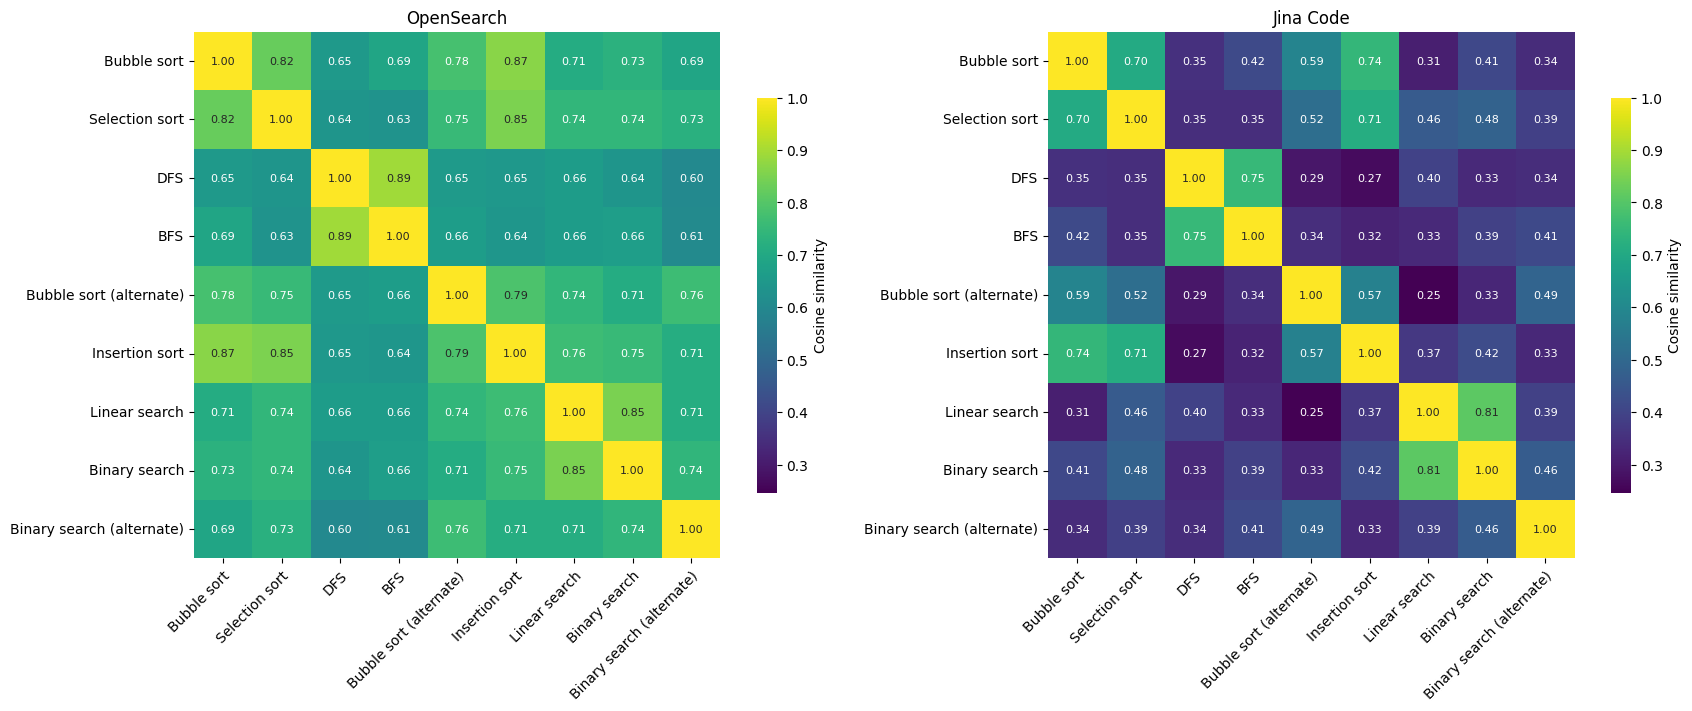

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

labels = list(examples)
matrices = {}

for name, encoder in models.items():
    vectors = encoder.encode(
        list(examples.values()),
        convert_to_numpy=True,
        normalize_embeddings=True,
    )
    matrices[name] = pd.DataFrame(
        vectors @ vectors.T, index=labels, columns=labels
    )

vmin = min(matrix.to_numpy().min() for matrix in matrices.values())
fig, axes = plt.subplots(
    1, len(matrices), figsize=(17, 7), layout="constrained"
)

for ax, (name, matrix) in zip(axes, matrices.items()):
    sns.heatmap(
        matrix, ax=ax, annot=True, fmt=".2f", cmap="viridis",
        vmin=vmin, vmax=1, square=True,
        annot_kws={"size": 8},
        cbar_kws={"label": "Cosine similarity", "shrink": 0.75},
    )
    ax.set_title(name)
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")

plt.show()

**Margin chart.** Compare how each model ranks the alternate implementation against the different algorithm in each check.

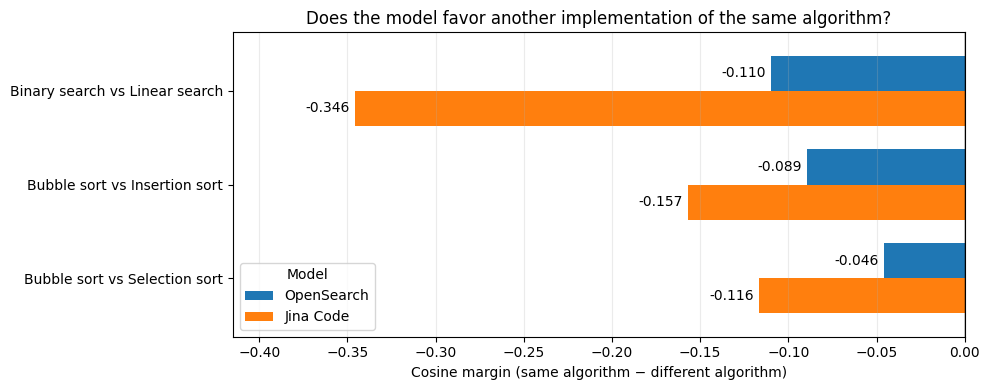

In [ ]:
plot_data = pd.DataFrame(results)
plot_data["Comparison"] = (
    plot_data["Anchor"] + " vs " + plot_data["Different algorithm"]
)

margins = plot_data.pivot(
    index="Comparison", columns="Model", values="Margin"
).reindex(columns=list(models))

ax = margins.plot.barh(figsize=(10, 4), width=0.75)
ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("Cosine margin (same algorithm − different algorithm)")
ax.set_ylabel("")
ax.set_title("Does the model favor another implementation of the same algorithm?")
ax.grid(axis="x", alpha=0.25)
ax.margins(x=0.2)
ax.invert_yaxis()

for bars in ax.containers:
    ax.bar_label(bars, fmt="%.3f", padding=4)

plt.tight_layout()
plt.show()

**Result.** In all three checks, both models scored the different algorithm higher than the alternate implementation.